# Explainable ML-Based Network Intrusion Detection System (NIDS)

An end-to-end machine learning project on the **NSL-KDD** benchmark that detects malicious network connections, classifies the attack type, **explains every alert with SHAP**, and turns predictions into **SOC-style alerts with recommended response actions**.

**How to run:** `Runtime -> Run all`. The notebook downloads the dataset by itself (no manual upload). Expected total runtime on free Colab CPU: roughly 15-20 minutes. To make it faster, lower `N_SPLITS` and `TUNE_ITER` in Section 2.

## 1. Project Introduction

### Problem Statement
Signature-based security tools miss novel attacks. Machine learning can learn what normal traffic looks like and flag suspicious behaviour, but analysts will not trust a black box. This project builds a detector that is accurate **and** explainable.

### Objectives
1. **Binary detection:** Normal vs Attack, with the priority on high *recall* (missed attacks are costly).
2. **Multi-class classification:** Normal, DoS, Probe, R2L, U2R.
3. **Explainability:** show *why* a connection was flagged using SHAP.
4. **Actionability:** convert predictions into severity levels and recommended response actions (SOAR-style alert log).

### Dataset
**NSL-KDD** (`KDDTrain+.txt`: 125,973 records, `KDDTest+.txt`: 22,544 records), 41 features per connection plus a label. The official test set deliberately contains attack types that never appear in training, so test scores are lower than random-split scores. That is realistic, and is discussed in the results.

### Workflow
Setup -> Data loading -> EDA -> Preprocessing -> Cross-validated training -> Tuning -> Test evaluation -> Threshold analysis -> Multi-class evaluation -> Explainability (SHAP) -> Error analysis -> Save artifacts -> Prediction demo and alert log -> Conclusion

## 2. Setup

**WHAT:** install `shap` and `xgboost`, import the libraries, fix the random seed, and set two run-time knobs (`N_SPLITS`, `TUNE_ITER`).

**WHY:** a fixed seed makes every run reproducible. The two knobs let you trade accuracy of the search for speed.

In [31]:
!pip install -q shap xgboost

import os, io, sys, shutil, random, warnings, urllib.request, subprocess
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             roc_curve, precision_recall_curve)
import xgboost as xgb
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

# ---- run-time knobs (lower them for a faster run) ----
N_SPLITS  = 5   # cross-validation folds
TUNE_ITER = 4   # random-search candidates per tuned model

os.makedirs("images", exist_ok=True)
os.makedirs("results", exist_ok=True)

def save_fig(name):
    """Save the current matplotlib figure into images/ (used later in the report)."""
    plt.savefig(f"images/{name}.png", dpi=130, bbox_inches="tight")

print("Setup complete. Seed =", RANDOM_SEED)

Setup complete. Seed = 42


## 3. Data Download and Loading

**WHAT:** download `KDDTrain+.txt` and `KDDTest+.txt` automatically. The code tries, in order: (1) public GitHub mirrors, (2) the Kaggle dataset `hassan06/nslkdd` through `kagglehub`, (3) a manual upload prompt as the last resort. Each downloaded file is validated (43 comma-separated fields per row) so a broken download is never used silently.

**WHY:** the raw NSL-KDD files have no header row, so we assign the 43 column names ourselves. We drop `difficulty` because it is a benchmark annotation, not a network feature.

In [32]:
COLUMNS = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty",
]

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)
TRAIN_FILE, TEST_FILE = "KDDTrain+.txt", "KDDTest+.txt"
train_path = os.path.join(DATA_DIR, TRAIN_FILE)
test_path  = os.path.join(DATA_DIR, TEST_FILE)

def is_valid_nsl_file(path):
    """True if the file exists, is not tiny/HTML, and rows have 43 comma-separated fields."""
    try:
        if not os.path.exists(path) or os.path.getsize(path) < 100_000:
            return False
        with open(path, "r", errors="ignore") as f:
            return len(f.readline().strip().split(",")) == 43
    except Exception:
        return False

def both_ready():
    return is_valid_nsl_file(train_path) and is_valid_nsl_file(test_path)

def try_mirror_download():
    from urllib.parse import quote
    mirrors = [
        "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/",
        "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/",
    ]
    for base in mirrors:
        try:
            print("Trying mirror:", base)
            urllib.request.urlretrieve(base + quote(TRAIN_FILE), train_path)
            urllib.request.urlretrieve(base + quote(TEST_FILE), test_path)
            if both_ready():
                print("Downloaded from mirror.")
                return True
        except Exception as e:
            print("  failed:", str(e)[:100])
    return False

def try_kaggle_download():
    try:
        print("Trying Kaggle dataset hassan06/nslkdd via kagglehub ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
        folder = kagglehub.dataset_download("hassan06/nslkdd")
        found = {}
        for root, _, files in os.walk(folder):
            for f in files:
                if f in (TRAIN_FILE, TEST_FILE):
                    found[f] = os.path.join(root, f)
        if len(found) == 2:
            shutil.copy(found[TRAIN_FILE], train_path)
            shutil.copy(found[TEST_FILE], test_path)
            if both_ready():
                print("Downloaded from Kaggle.")
                return True
    except Exception as e:
        print("  failed:", str(e)[:150])
    return False

def manual_upload():
    try:
        from google.colab import files
    except ImportError:
        return False
    print("Automatic download failed. Please upload KDDTrain+.txt and KDDTest+.txt now.")
    uploaded = files.upload()
    for name in uploaded:
        low = name.lower()
        if "train" in low:
            shutil.move(name, train_path)
        elif "test" in low:
            shutil.move(name, test_path)
    return both_ready()

if both_ready():
    print("Dataset files already present. Skipping download.")
else:
    ok = try_mirror_download() or try_kaggle_download() or manual_upload()
    if not ok:
        raise FileNotFoundError(
            "Could not obtain NSL-KDD. Download KDDTrain+.txt and KDDTest+.txt from "
            "https://www.kaggle.com/datasets/hassan06/nslkdd and put them in the 'data' folder.")

train_df = pd.read_csv(train_path, header=None, names=COLUMNS).drop(columns=["difficulty"])
test_df  = pd.read_csv(test_path,  header=None, names=COLUMNS).drop(columns=["difficulty"])

print(f"\nTrain shape: {train_df.shape}   (official file has 125,973 rows)")
print(f"Test  shape: {test_df.shape}   (official file has 22,544 rows)")
display(train_df.head(3))

Dataset files already present. Skipping download.

Train shape: (125973, 42)   (official file has 125,973 rows)
Test  shape: (22544, 42)   (official file has 22,544 rows)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.0,0.0,0.0,0.05,0.0,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.0,0.0,0.0,0.00,0.0,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.0,1.0,1.0,0.00,0.0,neptune


## 4. Exploratory Data Analysis (EDA)

**WHAT:** map the 38 specific attack names onto 5 categories (Normal, DoS, Probe, R2L, U2R), then plot class balance, protocol/service usage and feature correlations. Every chart is followed by numbers computed from the data, so the insight always matches what is on screen.

**WHY:** class imbalance and correlated features decide which metrics and models make sense later.

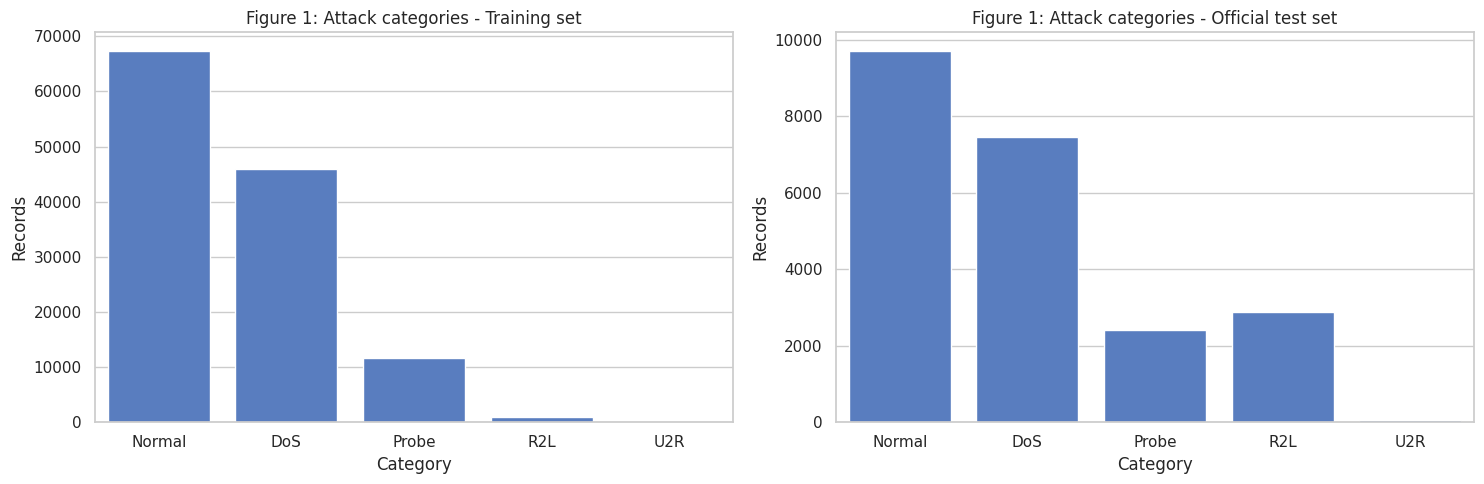

TRAIN: Normal: 67343 (53.5%) | DoS: 45927 (36.5%) | Probe: 11656 (9.3%) | R2L: 995 (0.8%) | U2R: 52 (0.0%)
TEST: Normal: 9711 (43.1%) | DoS: 7460 (33.1%) | Probe: 2421 (10.7%) | R2L: 2885 (12.8%) | U2R: 67 (0.3%)

Train attack ratio: 46.5%   Test attack ratio: 56.9%

Attack types that appear ONLY in the test set (17): ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']


In [33]:
attack_mapping = {
    "normal": "Normal",
    # Denial of Service
    "back": "DoS", "land": "DoS", "neptune": "DoS", "pod": "DoS", "smurf": "DoS", "teardrop": "DoS",
    "apache2": "DoS", "udpstorm": "DoS", "processtable": "DoS", "mailbomb": "DoS", "worm": "DoS",
    # Probe / scanning
    "satan": "Probe", "ipsweep": "Probe", "nmap": "Probe", "portsweep": "Probe", "mscan": "Probe", "saint": "Probe",
    # Remote to Local
    "guess_passwd": "R2L", "ftp_write": "R2L", "imap": "R2L", "phf": "R2L", "multihop": "R2L",
    "warezmaster": "R2L", "warezclient": "R2L", "spy": "R2L", "xlock": "R2L", "xsnoop": "R2L",
    "snmpguess": "R2L", "snmpgetattack": "R2L", "httptunnel": "R2L", "sendmail": "R2L", "named": "R2L",
    # User to Root
    "buffer_overflow": "U2R", "loadmodule": "U2R", "rootkit": "U2R", "perl": "U2R",
    "sqlattack": "U2R", "xterm": "U2R", "ps": "U2R",
}
CLASS_NAMES = ["Normal", "DoS", "Probe", "R2L", "U2R"]

for df in (train_df, test_df):
    df["category"] = df["label"].map(attack_mapping)
    df["target"] = (df["label"] != "normal").astype(int)   # 0 = Normal, 1 = Attack

unmapped = set(train_df.loc[train_df["category"].isna(), "label"]) | set(test_df.loc[test_df["category"].isna(), "label"])
assert not unmapped, f"Unmapped attack labels found: {unmapped}"

# ---- Figure 1 & 2: class balance ----
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, df, title in zip(axes, (train_df, test_df), ("Training set", "Official test set")):
    sns.countplot(data=df, x="category", order=CLASS_NAMES, ax=ax)
    ax.set_title(f"Figure 1: Attack categories - {title}")
    ax.set_xlabel("Category"); ax.set_ylabel("Records")
plt.tight_layout(); save_fig("fig1_class_distribution"); plt.show()

for name, df in (("TRAIN", train_df), ("TEST", test_df)):
    vc = df["category"].value_counts().reindex(CLASS_NAMES)
    print(f"{name}: " + " | ".join(f"{k}: {v} ({v/len(df)*100:.1f}%)" for k, v in vc.items()))
print(f"\nTrain attack ratio: {train_df['target'].mean()*100:.1f}%   Test attack ratio: {test_df['target'].mean()*100:.1f}%")

new_in_test = sorted(set(test_df["label"]) - set(train_df["label"]))
print(f"\nAttack types that appear ONLY in the test set ({len(new_in_test)}): {new_in_test}")

**Security insight:** the binary split (Normal vs Attack) is fairly balanced, but the 5-class view is not. R2L and especially U2R are tiny classes, so a model can score high accuracy while still missing them. The test set also contains attack types never seen in training (listed above), which is why test performance will be lower than cross-validation performance.

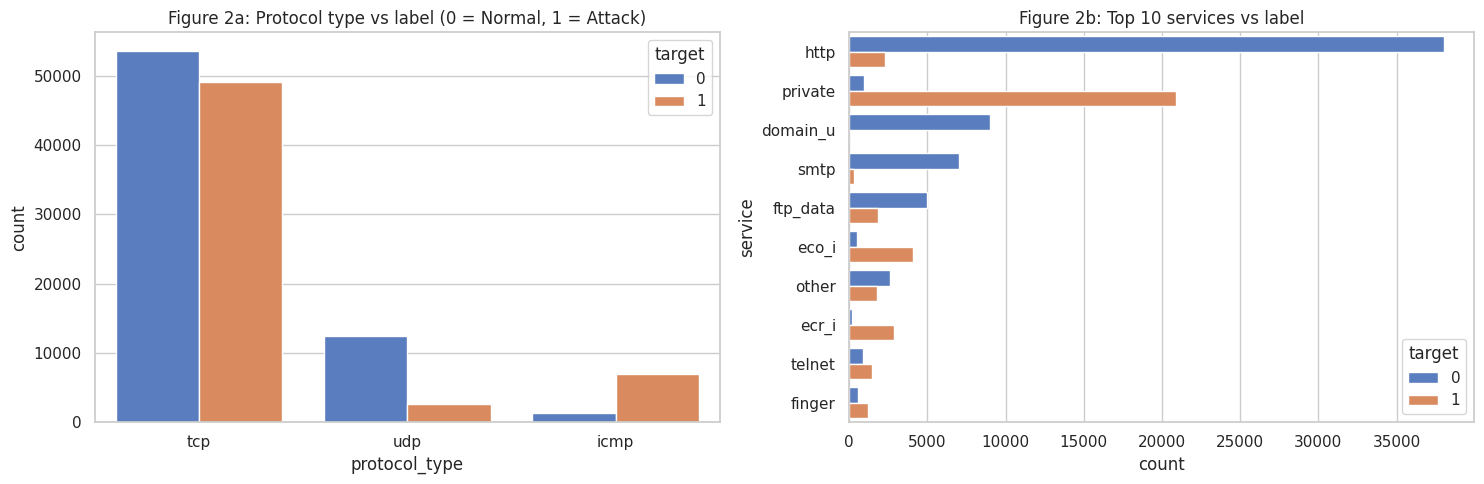

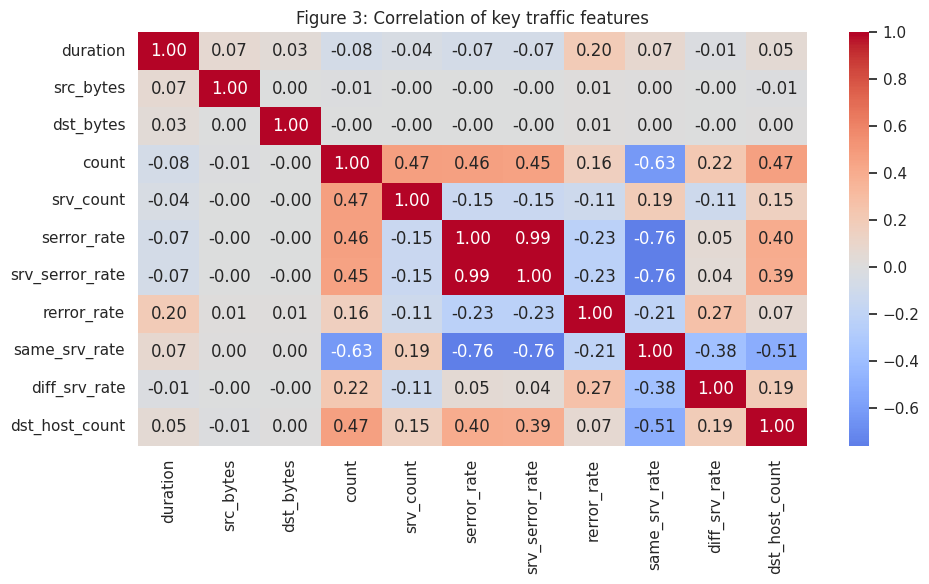

Most correlated feature pairs:
  serror_rate  <->  srv_serror_rate: 0.99
  serror_rate  <->  same_srv_rate: -0.76
  srv_serror_rate  <->  same_srv_rate: -0.76

Missing values (train): 0
Duplicate rows (train): 0


In [34]:
# ---- Figure 2: protocols and services ----
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=train_df, x="protocol_type", hue="target", ax=axes[0])
axes[0].set_title("Figure 2a: Protocol type vs label (0 = Normal, 1 = Attack)")
top_services = train_df["service"].value_counts().head(10).index
sns.countplot(data=train_df[train_df["service"].isin(top_services)], y="service",
              order=top_services, hue="target", ax=axes[1])
axes[1].set_title("Figure 2b: Top 10 services vs label")
plt.tight_layout(); save_fig("fig2_protocol_service"); plt.show()

# ---- Figure 3: correlation of key traffic features ----
key_numeric = ["duration", "src_bytes", "dst_bytes", "count", "srv_count", "serror_rate",
               "srv_serror_rate", "rerror_rate", "same_srv_rate", "diff_srv_rate", "dst_host_count"]
corr = train_df[key_numeric].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Figure 3: Correlation of key traffic features")
plt.tight_layout(); save_fig("fig3_correlation"); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().sort_values(key=abs, ascending=False)
print("Most correlated feature pairs:")
for (a, b), v in pairs.head(3).items():
    print(f"  {a}  <->  {b}: {v:.2f}")

print(f"\nMissing values (train): {int(train_df.isnull().sum().sum())}")
print(f"Duplicate rows (train): {int(train_df.duplicated().sum())}")

**Security insight:** SYN-error features (`serror_rate`, `srv_serror_rate`) move together almost perfectly, because a SYN flood raises both. Highly correlated features can destabilise linear models, while tree-based models handle them without trouble. There are no missing values, and NSL-KDD was built with duplicates already removed.

## 5. Data Preprocessing

**WHAT:**
1. Separate the features from the targets (`target` for binary, `category` for multi-class).
2. Scale the numeric features with `StandardScaler`.
3. One-hot encode `protocol_type`, `service` and `flag` with `handle_unknown="ignore"`.
4. Wrap all of this in a `ColumnTransformer` that lives **inside** every model pipeline.

**WHY:** because preprocessing is part of the pipeline, it is re-fitted on the training portion of each cross-validation fold only. That prevents **data leakage**, a mistake that silently inflates scores. `handle_unknown="ignore"` matters because the test set contains services that never appear in training.

In [35]:
FEATURE_COLS = [c for c in COLUMNS if c not in ("label", "difficulty")]
CAT_FEATURES = ["protocol_type", "service", "flag"]
NUM_FEATURES = [c for c in FEATURE_COLS if c not in CAT_FEATURES]

X_train_raw, y_train = train_df[FEATURE_COLS], train_df["target"]
X_test_raw,  y_test  = test_df[FEATURE_COLS],  test_df["target"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUM_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES),
])

# Fit once ONLY to show the final feature count (pipelines below re-fit it on their own training data).
_demo = clone(preprocessor).fit(X_train_raw)
print(f"Raw features: {len(FEATURE_COLS)}  ->  after encoding: {len(_demo.get_feature_names_out())}")
print(f"Numeric: {len(NUM_FEATURES)} | Categorical: {len(CAT_FEATURES)}")

def make_pipeline(clf):
    """Preprocessing + classifier in one object (no leakage, easy to save and deploy)."""
    return Pipeline([("prep", clone(preprocessor)), ("clf", clf)])

Raw features: 41  ->  after encoding: 122
Numeric: 38 | Categorical: 3


## 6. Model Training Pipeline

**WHAT:** build four pipelines (Logistic Regression, Decision Tree, Random Forest, XGBoost), handle class imbalance (`class_weight="balanced"` / `scale_pos_weight`), and compare them with Stratified K-Fold cross-validation on the **training set**.

**WHY:** cross-validation gives a more trustworthy estimate than one split, and comparing several algorithms shows that the final model was chosen on evidence.

In [36]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_SEED),
    "Decision Tree":       DecisionTreeClassifier(class_weight="balanced", max_depth=20, random_state=RANDOM_SEED),
    "Random Forest":       RandomForestClassifier(class_weight="balanced", n_estimators=100, max_depth=20,
                                                  n_jobs=-1, random_state=RANDOM_SEED),
    "XGBoost":             xgb.XGBClassifier(scale_pos_weight=neg / pos, n_estimators=100, eval_metric="logloss",
                                             n_jobs=-1, random_state=RANDOM_SEED),
}

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_rows = []
for name, clf in models.items():
    print(f"Cross-validating {name} ...")
    s = cross_validate(make_pipeline(clf), X_train_raw, y_train, cv=skf, scoring=scoring)
    cv_rows.append({"Model": name,
                    "CV Accuracy":  s["test_accuracy"].mean(),
                    "CV Precision": s["test_precision"].mean(),
                    "CV Recall":    s["test_recall"].mean(),
                    "CV F1":        s["test_f1"].mean(),
                    "CV ROC-AUC":   s["test_roc_auc"].mean()})

cv_df = pd.DataFrame(cv_rows)
cv_df.round(4).to_csv("results/cross_validation_results.csv", index=False)
display(cv_df.round(4))

Cross-validating Logistic Regression ...
Cross-validating Decision Tree ...
Cross-validating Random Forest ...
Cross-validating XGBoost ...


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
0,Logistic Regression,0.9739,0.9765,0.9672,0.9718,0.9964
1,Decision Tree,0.9985,0.9983,0.9984,0.9983,0.9985
2,Random Forest,0.9988,0.9995,0.9979,0.9987,1.0000
3,XGBoost,0.9991,0.9993,0.9988,0.9990,1.0000


Cross-validation scores are usually very high on NSL-KDD because every fold is drawn from the same training distribution. The honest test is the official `KDDTest+` set in Section 8.

## 7. Hyperparameter Tuning

**WHAT:** run a small `RandomizedSearchCV` on the two strongest tree ensembles, Random Forest and XGBoost, optimising F1.

**WHY:** limiting tree depth and learning rate reduces overfitting and keeps the saved model file small enough to upload to GitHub.

In [37]:
rf_search = RandomizedSearchCV(
    make_pipeline(RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_SEED)),
    param_distributions={
        "clf__n_estimators": [100, 150],
        "clf__max_depth": [12, 20, 30],
        "clf__min_samples_leaf": [1, 2, 5],
    },
    n_iter=TUNE_ITER, cv=3, scoring="f1", random_state=RANDOM_SEED, n_jobs=1)
print("Tuning Random Forest ...")
rf_search.fit(X_train_raw, y_train)
print("Best RF params :", rf_search.best_params_)

xgb_search = RandomizedSearchCV(
    make_pipeline(xgb.XGBClassifier(scale_pos_weight=neg / pos, eval_metric="logloss",
                                    n_jobs=-1, random_state=RANDOM_SEED)),
    param_distributions={
        "clf__n_estimators": [100, 200],
        "clf__max_depth": [3, 6, 9],
        "clf__learning_rate": [0.05, 0.1, 0.2],
    },
    n_iter=TUNE_ITER, cv=3, scoring="f1", random_state=RANDOM_SEED, n_jobs=1)
print("Tuning XGBoost ...")
xgb_search.fit(X_train_raw, y_train)
print("Best XGB params:", xgb_search.best_params_)

Tuning Random Forest ...
Best RF params : {'clf__n_estimators': 100, 'clf__min_samples_leaf': 2, 'clf__max_depth': 20}
Tuning XGBoost ...
Best XGB params: {'clf__n_estimators': 200, 'clf__max_depth': 9, 'clf__learning_rate': 0.05}


## 8. Evaluation on the Official Test Set (`KDDTest+`)

**WHAT:** fit all four models on the full training set, then score them on `KDDTest+`: accuracy, precision, recall, F1, ROC-AUC, confusion matrices and ROC curves.

**WHY recall matters most:** a false positive wastes an analyst's time; a **false negative is an intruder who got in unnoticed**. So in intrusion detection we watch recall (the share of real attacks caught) more closely than accuracy.

**Expect lower numbers than in cross-validation.** The test set contains attack types the models never saw, which is exactly the zero-day situation a real IDS faces.

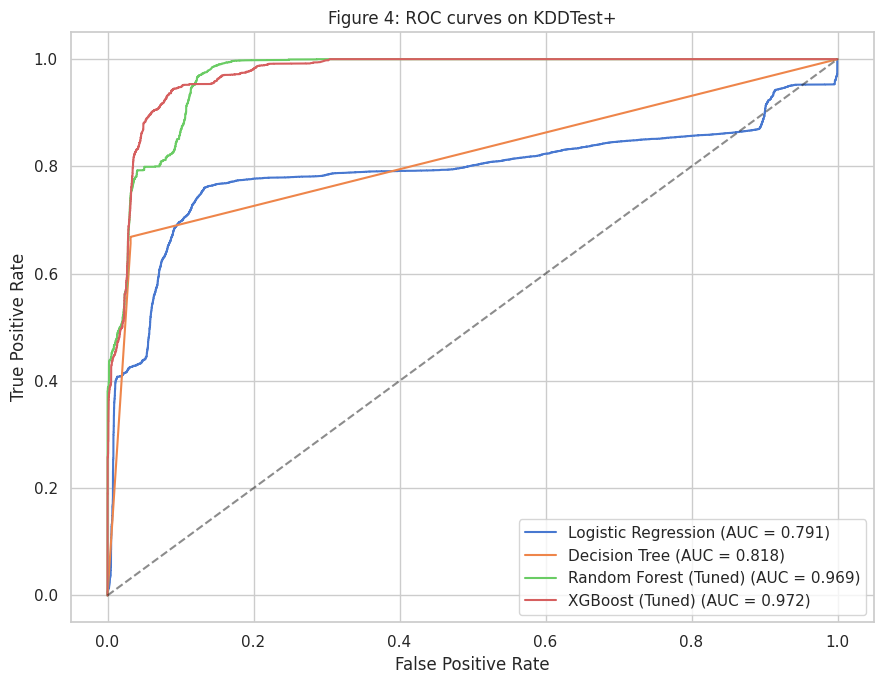

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7547,0.9170,0.6257,0.7438,0.7912
1,Decision Tree,0.7976,0.9654,0.6684,0.7899,0.8183
2,Random Forest (Tuned),0.7698,0.9676,0.6162,0.7529,0.9686
3,XGBoost (Tuned),0.8031,0.9690,0.6757,0.7962,0.9723


In [38]:
final_models = {
    "Logistic Regression":   make_pipeline(models["Logistic Regression"]).fit(X_train_raw, y_train),
    "Decision Tree":         make_pipeline(models["Decision Tree"]).fit(X_train_raw, y_train),
    "Random Forest (Tuned)": rf_search.best_estimator_,
    "XGBoost (Tuned)":       xgb_search.best_estimator_,
}

test_probs, test_rows = {}, []
plt.figure(figsize=(9, 7))
for name, model in final_models.items():
    probs = model.predict_proba(X_test_raw)[:, 1]
    pred = (probs >= 0.5).astype(int)
    test_probs[name] = probs
    test_rows.append({"Model": name,
                      "Accuracy":  accuracy_score(y_test, pred),
                      "Precision": precision_score(y_test, pred),
                      "Recall":    recall_score(y_test, pred),
                      "F1-Score":  f1_score(y_test, pred),
                      "ROC-AUC":   roc_auc_score(y_test, probs)})
    fpr, tpr, _ = roc_curve(y_test, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {test_rows[-1]['ROC-AUC']:.3f})")

plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("Figure 4: ROC curves on KDDTest+")
plt.legend(loc="lower right"); plt.tight_layout(); save_fig("fig4_roc_curves"); plt.show()

test_score_df = pd.DataFrame(test_rows)
test_score_df.round(4).to_csv("results/test_set_results.csv", index=False)
display(test_score_df.round(4))

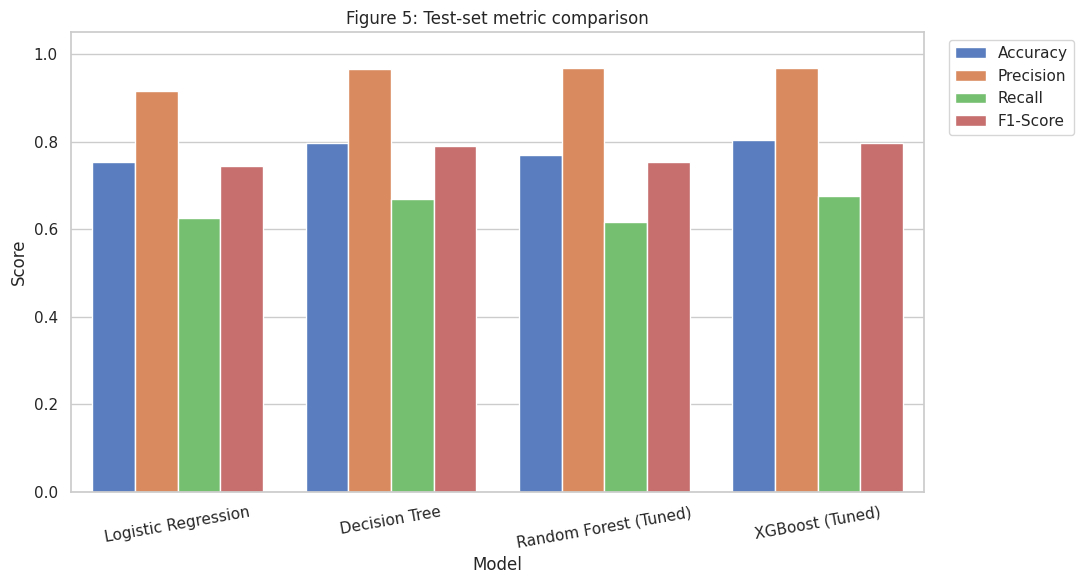

Champion model (best F1 among tree ensembles): XGBoost (Tuned)


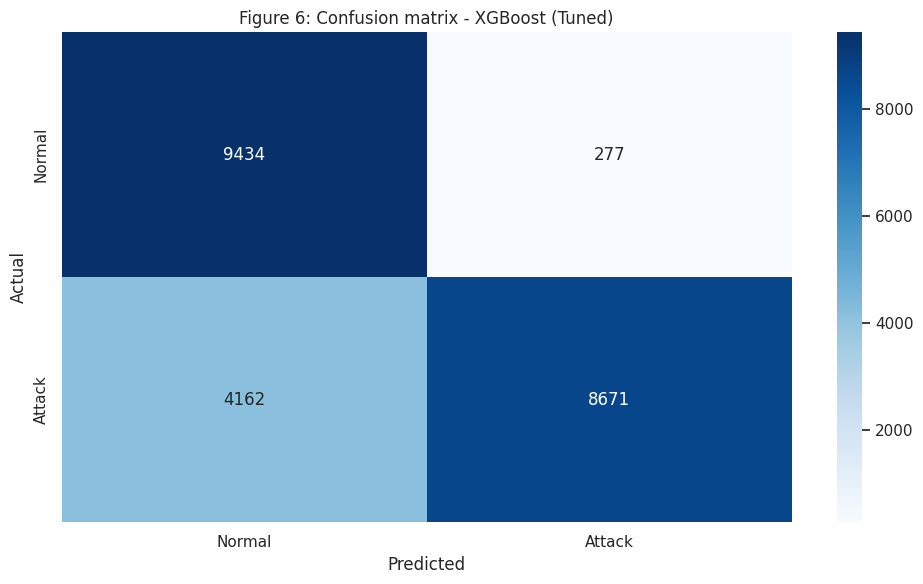

Caught attacks (TP): 8671 | Missed attacks (FN): 4162 | False alarms (FP): 277 | Correct normal (TN): 9434
Attack recall: 67.6%   False-alarm rate: 2.9%


In [39]:
# ---- Figure 5: metric comparison ----
melted = test_score_df.melt(id_vars="Model", value_vars=["Accuracy", "Precision", "Recall", "F1-Score"],
                            var_name="Metric", value_name="Score")
plt.figure(figsize=(11, 6))
sns.barplot(data=melted, x="Model", y="Score", hue="Metric")
plt.ylim(0, 1.05); plt.title("Figure 5: Test-set metric comparison")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.xticks(rotation=10)
plt.tight_layout(); save_fig("fig5_metric_comparison"); plt.show()

# ---- Pick the champion among the tree ensembles (both work with SHAP) ----
candidates = ["Random Forest (Tuned)", "XGBoost (Tuned)"]
champion_name = test_score_df[test_score_df["Model"].isin(candidates)].sort_values("F1-Score", ascending=False)["Model"].iloc[0]
champion = final_models[champion_name]
champ_probs = test_probs[champion_name]
champ_pred = (champ_probs >= 0.5).astype(int)
print(f"Champion model (best F1 among tree ensembles): {champion_name}")

# ---- Figure 6: confusion matrix of the champion ----
cm = confusion_matrix(y_test, champ_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"])
plt.title(f"Figure 6: Confusion matrix - {champion_name}")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); save_fig("fig6_confusion_matrix"); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Caught attacks (TP): {tp} | Missed attacks (FN): {fn} | False alarms (FP): {fp} | Correct normal (TN): {tn}")
print(f"Attack recall: {tp/(tp+fn)*100:.1f}%   False-alarm rate: {fp/(fp+tn)*100:.1f}%")

## 9. Threshold Analysis (tuning the detector for security)

**WHAT:** the default decision threshold is 0.5. A real SOC can choose a lower threshold to catch more attacks, at the price of more false alarms. We measure that trade-off explicitly.

**WHY:** it shows that the model is not just trained, it is *operated* with a deliberate risk decision.

,Threshold,Attack Recall,Precision,False-Alarm Rate,Missed Attacks (FN)
0,0.5,0.6757,0.9690,0.0285,4162
1,0.4,0.6846,0.9693,0.0286,4047
2,0.3,0.6902,0.9688,0.0293,3976
3,0.2,0.6958,0.9689,0.0296,3904
4,0.1,0.7166,0.9684,0.0309,3637


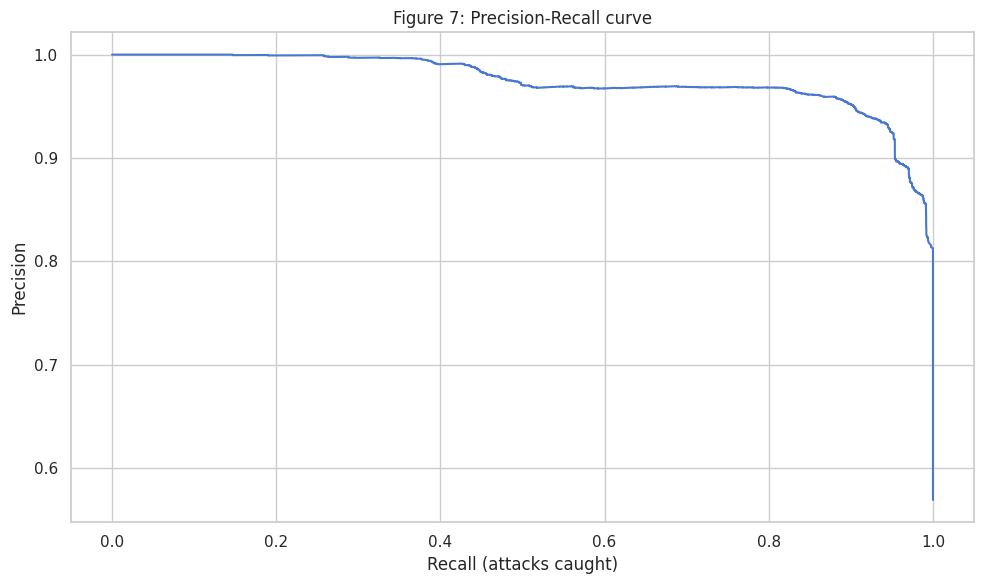

In [40]:
rows = []
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    pred_t = (champ_probs >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, pred_t).ravel()
    rows.append({"Threshold": t,
                 "Attack Recall": tp_ / (tp_ + fn_),
                 "Precision": tp_ / (tp_ + fp_) if (tp_ + fp_) else 0,
                 "False-Alarm Rate": fp_ / (fp_ + tn_),
                 "Missed Attacks (FN)": fn_})
threshold_df = pd.DataFrame(rows)
threshold_df.round(4).to_csv("results/threshold_analysis.csv", index=False)
display(threshold_df.round(4))

prec, rec, _ = precision_recall_curve(y_test, champ_probs)
plt.plot(rec, prec)
plt.xlabel("Recall (attacks caught)"); plt.ylabel("Precision")
plt.title("Figure 7: Precision-Recall curve")
plt.tight_layout(); save_fig("fig7_precision_recall"); plt.show()

Lowering the threshold raises recall (fewer missed attacks) while precision falls (more false alarms). Which point is right depends on how costly a miss is compared with an analyst's time. For a high-value network, a lower threshold is usually preferred.

## 10. Multi-class Evaluation (attack categories)

**WHAT:** train a Random Forest pipeline that predicts one of five classes: Normal, DoS, Probe, R2L, U2R.

**WHY:** responders need to know *what kind* of attack is happening. We expect U2R and R2L to be hard, because they look like normal user activity rather than noisy floods, and they are very rare in the training data.

              precision    recall  f1-score   support

      Normal       0.65      0.97      0.78      9711
         DoS       0.96      0.81      0.88      7460
       Probe       0.86      0.60      0.70      2421
         R2L       0.93      0.01      0.02      2885
         U2R       0.50      0.03      0.06        67

    accuracy                           0.75     22544
   macro avg       0.78      0.48      0.49     22544
weighted avg       0.81      0.75      0.70     22544



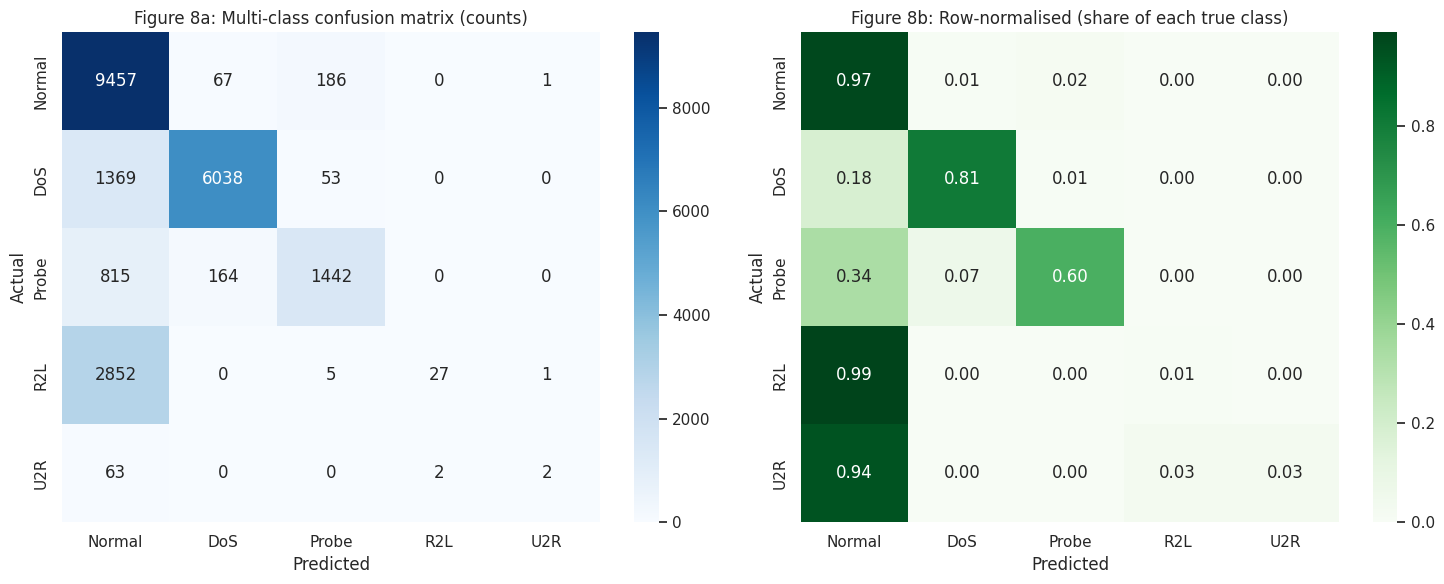

In [41]:
class_map = {n: i for i, n in enumerate(CLASS_NAMES)}
y_train_multi = train_df["category"].map(class_map)
y_test_multi  = test_df["category"].map(class_map)

multi_model = make_pipeline(RandomForestClassifier(class_weight="balanced", n_estimators=100, max_depth=20,
                                                   n_jobs=-1, random_state=RANDOM_SEED))
multi_model.fit(X_train_raw, y_train_multi)
y_pred_multi = multi_model.predict(X_test_raw)

report = classification_report(y_test_multi, y_pred_multi, labels=range(5), target_names=CLASS_NAMES,
                               zero_division=0, output_dict=True)
print(classification_report(y_test_multi, y_pred_multi, labels=range(5), target_names=CLASS_NAMES, zero_division=0))
pd.DataFrame(report).T.round(4).to_csv("results/multiclass_report.csv")

cm_m = confusion_matrix(y_test_multi, y_pred_multi, labels=range(5))
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(cm_m, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title("Figure 8a: Multi-class confusion matrix (counts)")
cm_norm = cm_m / cm_m.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_title("Figure 8b: Row-normalised (share of each true class)")
for ax in axes:
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); save_fig("fig8_multiclass_confusion"); plt.show()

**Analysis of weak classes:** check the recall of R2L and U2R in the report above. These attacks target authentication and host-level weaknesses, so their network footprint looks like normal user behaviour, and U2R has only a few dozen training examples. Detecting them reliably needs host logs or application-layer inspection in addition to flow statistics.

## 11. Feature Importance and Explainability (SHAP)

**WHAT:** (1) global feature importance from the champion model, (2) a SHAP summary plot over 500 random test connections, (3) a SHAP waterfall explaining **one specific flagged attack**.

**WHY:** importance scores say what matters overall. SHAP says *how each feature pushed this particular connection towards "attack" or "normal"*, which is the auditable reasoning a security analyst needs before acting on an alert.

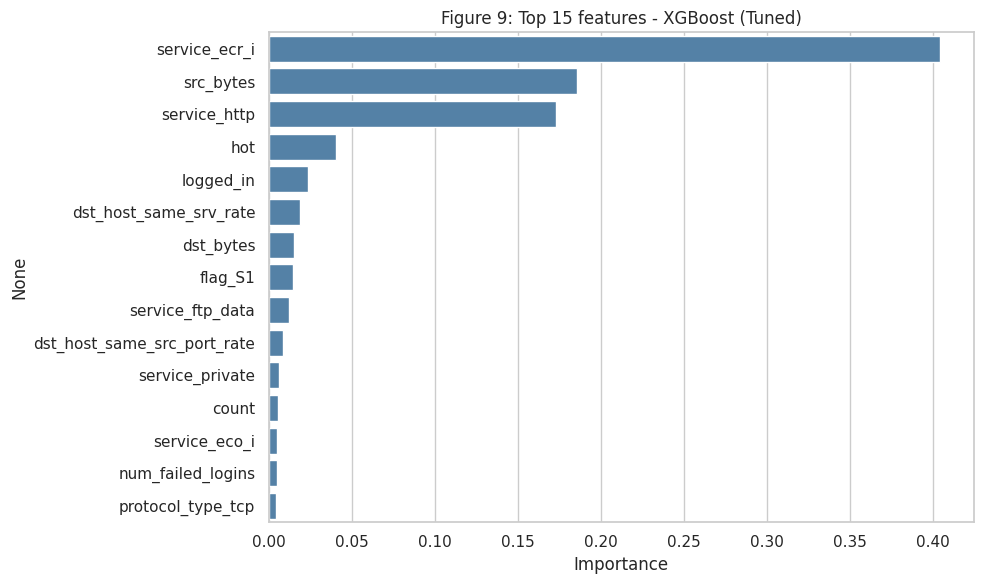

In [42]:
prep_fitted = champion.named_steps["prep"]
clf_fitted  = champion.named_steps["clf"]
feature_names = [n.split("__", 1)[1] for n in prep_fitted.get_feature_names_out()]

# ---- Figure 9: global importance ----
imp = pd.Series(clf_fitted.feature_importances_, index=feature_names).sort_values(ascending=False).head(15)
sns.barplot(x=imp.values, y=imp.index, color="steelblue")
plt.title(f"Figure 9: Top 15 features - {champion_name}")
plt.xlabel("Importance"); plt.tight_layout(); save_fig("fig9_feature_importance"); plt.show()

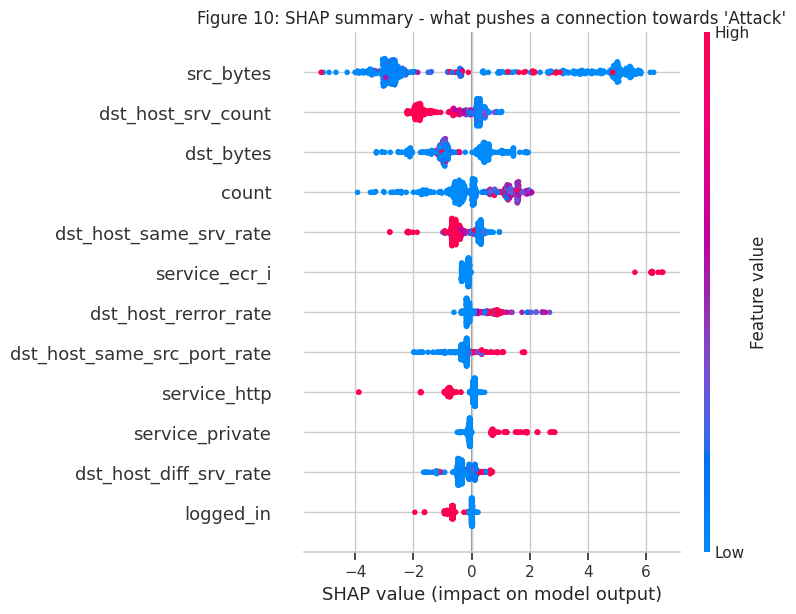

In [43]:
# ---- SHAP on a random 500-row sample of the test set ----
rng = np.random.RandomState(RANDOM_SEED)
sample_idx = rng.choice(len(X_test_raw), size=500, replace=False)
X_sample = prep_fitted.transform(X_test_raw.iloc[sample_idx])

explainer = shap.TreeExplainer(clf_fitted)
shap_values = explainer.shap_values(X_sample)

# Different SHAP versions return different shapes; normalise to (n_samples, n_features) for the "Attack" class.
if isinstance(shap_values, list):
    sv = np.array(shap_values[1])
elif np.ndim(shap_values) == 3:
    sv = shap_values[:, :, 1]
else:
    sv = np.array(shap_values)

base = explainer.expected_value
base_value = float(base[1]) if np.ndim(base) > 0 and len(np.atleast_1d(base)) > 1 else float(np.atleast_1d(base)[0])

plt.figure()
shap.summary_plot(sv, X_sample, feature_names=feature_names, max_display=12, show=False)
plt.title("Figure 10: SHAP summary - what pushes a connection towards 'Attack'")
plt.tight_layout(); save_fig("fig10_shap_summary"); plt.show()

Explaining test record # 14984 | true label: neptune | attack probability: 1.0


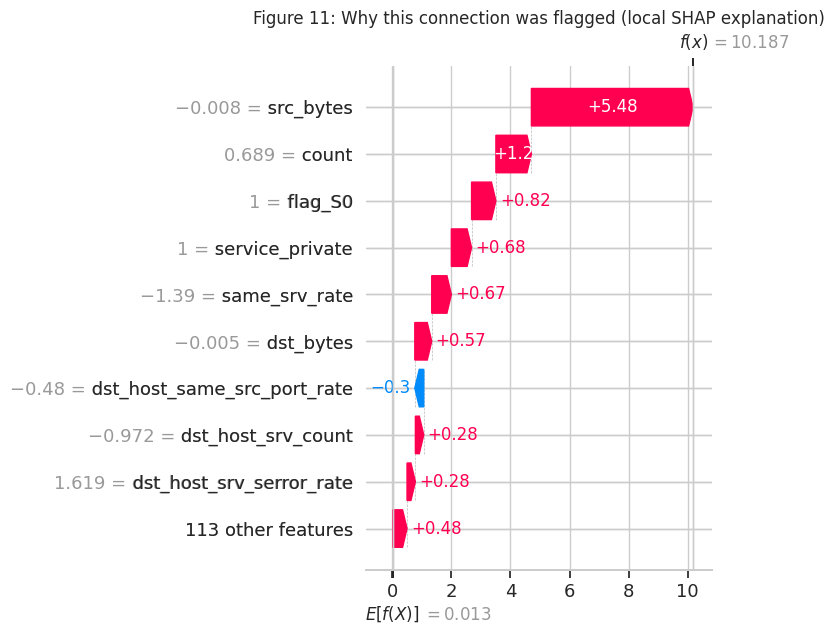

In [44]:
# ---- Explain ONE flagged attack: the highest-confidence true attack in the sample ----
sample_probs = champ_probs[sample_idx]
sample_true  = y_test.iloc[sample_idx].values
attack_positions = np.where(sample_true == 1)[0]
pick = attack_positions[np.argmax(sample_probs[attack_positions])]
print("Explaining test record #", int(sample_idx[pick]),
      "| true label:", test_df['label'].iloc[sample_idx[pick]],
      "| attack probability:", round(float(sample_probs[pick]), 4))

explanation = shap.Explanation(values=sv[pick], base_values=base_value,
                               data=X_sample[pick], feature_names=feature_names)
shap.plots.waterfall(explanation, max_display=10, show=False)
plt.title("Figure 11: Why this connection was flagged (local SHAP explanation)")
plt.tight_layout(); save_fig("fig11_shap_local"); plt.show()

## 12. Error Analysis

**WHAT:** look at *which* attacks the champion model misses (false negatives) and which normal connections it wrongly flags (false positives).

**WHY:** knowing the blind spots tells the security team where to add other controls, and tells us what to improve next.

False Negatives (missed attacks): 4162
False Positives (false alarms)  : 277

Share of each attack category that was MISSED (%):
category
DoS      12.0
Probe    24.3
R2L      91.0
U2R      80.6

Top 10 individual attack types that were missed:
label
guess_passwd       1231
warezmaster         697
mscan               588
processtable        432
snmpguess           331
mailbomb            293
snmpgetattack       178
apache2             158
httptunnel          130
buffer_overflow      16


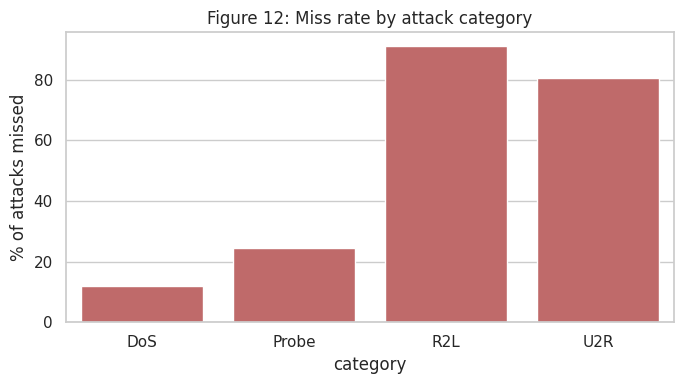


Example missed attack:


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
4,1,tcp,telnet,RSTO,0,15,0,0,0,0,...,29,86,0.31,0.17,0.03,0.02,0.0,0.0,0.83,0.71


Example false alarm:


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
33,0,udp,private,SF,1,1,0,0,0,0,...,255,3,0.01,0.58,0.99,0.0,0.0,0.0,0.01,0.0


In [45]:
fn_mask = (y_test.values == 1) & (champ_pred == 0)
fp_mask = (y_test.values == 0) & (champ_pred == 1)
print(f"False Negatives (missed attacks): {fn_mask.sum()}")
print(f"False Positives (false alarms)  : {fp_mask.sum()}")

missed = test_df.loc[fn_mask, "category"].value_counts()
totals = test_df.loc[test_df["target"] == 1, "category"].value_counts()
miss_rate = (missed / totals).reindex(["DoS", "Probe", "R2L", "U2R"]).fillna(0) * 100
print("\nShare of each attack category that was MISSED (%):")
print(miss_rate.round(1).to_string())

print("\nTop 10 individual attack types that were missed:")
print(test_df.loc[fn_mask, "label"].value_counts().head(10).to_string())

plt.figure(figsize=(7, 4))
sns.barplot(x=miss_rate.index, y=miss_rate.values, color="indianred")
plt.ylabel("% of attacks missed"); plt.title("Figure 12: Miss rate by attack category")
plt.tight_layout(); save_fig("fig12_miss_rate"); plt.show()

if fn_mask.sum():
    print("\nExample missed attack:"); display(X_test_raw[fn_mask].head(1))
if fp_mask.sum():
    print("Example false alarm:");   display(X_test_raw[fp_mask].head(1))

Attack types that are rare in training or absent from it are the ones most likely to slip through. This is the main limitation of a supervised detector, and it motivates anomaly-detection and deep-learning approaches in the future work.

## 13. Save Artifacts

**WHAT:** save the champion pipeline (preprocessing + model together), the multi-class pipeline, and a metadata file with the column lists.

**WHY:** these files are what the Streamlit dashboard loads. Because preprocessing is inside the pipeline, the dashboard can pass raw connection data straight in. `compress=3` keeps the file small for GitHub's 100 MB limit.

In [46]:
joblib.dump(champion, "model.pkl", compress=3)
joblib.dump(multi_model, "multiclass_model.pkl", compress=3)
joblib.dump(prep_fitted, "scaler.pkl", compress=3)          # fitted preprocessor (scaler + encoder)
joblib.dump({
    "raw_features": FEATURE_COLS,
    "numeric_features": NUM_FEATURES,
    "categorical_features": CAT_FEATURES,
    "processed_feature_names": feature_names,
    "class_names": CLASS_NAMES,
    "champion_name": champion_name,
}, "columns.pkl")

for f in ["model.pkl", "multiclass_model.pkl", "scaler.pkl", "columns.pkl"]:
    size_mb = os.path.getsize(f) / 1e6
    flag = "   <-- WARNING: over GitHub's 100 MB limit!" if size_mb > 95 else ""
    print(f"{f:24s} {size_mb:8.2f} MB{flag}")
print("Charts saved in images/:", sorted(os.listdir("images")))

model.pkl                    0.39 MB
multiclass_model.pkl         3.93 MB
scaler.pkl                   0.00 MB
columns.pkl                  0.00 MB
Charts saved in images/: ['fig10_shap_summary.png', 'fig11_shap_local.png', 'fig12_miss_rate.png', 'fig1_class_distribution.png', 'fig2_protocol_service.png', 'fig3_correlation.png', 'fig4_roc_curves.png', 'fig5_metric_comparison.png', 'fig6_confusion_matrix.png', 'fig7_precision_recall.png', 'fig8_multiclass_confusion.png', 'fig9_feature_importance.png']


## 14. Prediction Demo and SOC Alert Log

**WHAT:** `predict_connection()` takes one raw connection and returns the verdict, the attack probability, a severity level and a recommended response action. We then run it over 300 test connections and write every High/Critical result to `alerts_log.csv`, like a minimal SOAR playbook.

**WHY:** a detector is only useful if it drives a decision. Severity tiers turn a probability into an action an analyst or an automation can take.

In [47]:
def predict_connection(raw_row_df, model=champion):
    """Classify one raw connection and return verdict, probability, severity and recommended action."""
    prob = float(model.predict_proba(raw_row_df)[0][1])
    if prob < 0.50:
        verdict, severity, action = "Normal", "Low", "No action. Log to traffic database."
    elif prob < 0.70:
        verdict, severity, action = "Attack", "Medium", "Monitor closely and flag for review in the SIEM."
    elif prob < 0.90:
        verdict, severity, action = "Attack", "High", "Alert the SOC and rate-limit the source."
    else:
        verdict, severity, action = "Attack", "Critical", "Block the source IP and isolate the target host."
    return {"Prediction": verdict, "Attack Probability": f"{prob*100:.2f}%",
            "Severity": severity, "Recommended Action": action, "_prob": prob}

# ---- demo on 3 real attacks and 2 normal connections from the test set ----
demo_idx = list(test_df.index[test_df["target"] == 1][:3]) + list(test_df.index[test_df["target"] == 0][:2])
for i in demo_idx:
    out = predict_connection(X_test_raw.loc[[i]])
    print(f"\nConnection #{i}  (true label: {test_df.loc[i, 'label']})")
    for k, v in out.items():
        if not k.startswith("_"):
            print(f"  {k}: {v}")


Connection #0  (true label: neptune)
  Prediction: Attack
  Attack Probability: 99.99%
  Severity: Critical
  Recommended Action: Block the source IP and isolate the target host.

Connection #1  (true label: neptune)
  Prediction: Attack
  Attack Probability: 99.99%
  Severity: Critical
  Recommended Action: Block the source IP and isolate the target host.

Connection #3  (true label: saint)
  Prediction: Attack
  Attack Probability: 99.59%
  Severity: Critical
  Recommended Action: Block the source IP and isolate the target host.

Connection #2  (true label: normal)
  Prediction: Normal
  Attack Probability: 0.09%
  Severity: Low
  Recommended Action: No action. Log to traffic database.

Connection #5  (true label: normal)
  Prediction: Normal
  Attack Probability: 0.00%
  Severity: Low
  Recommended Action: No action. Log to traffic database.


In [48]:
# ---- SOAR-style alert log over 300 test connections ----
batch = X_test_raw.iloc[:300]
probs = champion.predict_proba(batch)[:, 1]

alerts = []
for (idx, row), p in zip(batch.iterrows(), probs):
    if p < 0.5:
        continue
    res = predict_connection(batch.loc[[idx]])
    alerts.append({
        "timestamp": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "connection_id": idx,
        "protocol": row["protocol_type"],
        "service": row["service"],
        "src_bytes": row["src_bytes"],
        "attack_probability": round(p, 4),
        "severity": res["Severity"],
        "recommended_action": res["Recommended Action"],
        "actual_label": test_df.loc[idx, "label"],
    })

alerts_df = pd.DataFrame(alerts)
alerts_df.to_csv("alerts_log.csv", index=False)
print(f"{len(alerts_df)} alerts raised out of {len(batch)} connections. Saved to alerts_log.csv")
print("\nSeverity breakdown:")
print(alerts_df["severity"].value_counts().to_string())
display(alerts_df.head(8))

118 alerts raised out of 300 connections. Saved to alerts_log.csv

Severity breakdown:
severity
Critical    109
High          6
Medium        3


,timestamp,connection_id,protocol,service,src_bytes,attack_probability,severity,recommended_action,actual_label
0,2026-10-22 19:26:51,0,tcp,private,0,0.9999,Critical,Block the source IP and isolate the target host.,neptune
1,2026-10-22 19:26:51,1,tcp,private,0,0.9999,Critical,Block the source IP and isolate the target host.,neptune
2,2026-10-22 19:26:51,3,icmp,eco_i,20,0.9959,Critical,Block the source IP and isolate the target host.,saint
3,2026-10-22 19:26:51,12,tcp,private,0,1.0000,Critical,Block the source IP and isolate the target host.,neptune
4,2026-10-22 19:26:51,13,tcp,telnet,0,0.9996,Critical,Block the source IP and isolate the target host.,neptune
5,2026-10-22 19:26:51,19,tcp,private,0,0.9999,Critical,Block the source IP and isolate the target host.,neptune
6,2026-10-22 19:26:51,20,tcp,ldap,0,0.9999,Critical,Block the source IP and isolate the target host.,neptune
7,2026-10-22 19:26:51,21,tcp,pop_3,0,0.9929,Critical,Block the source IP and isolate the target host.,mscan


## 15. Final Results Summary

The next cell prints the headline numbers for your report and README, straight from this run.

In [49]:
best_row = test_score_df[test_score_df["Model"] == champion_name].iloc[0]
print("=" * 60)
print("FINAL RESULTS (official KDDTest+ set)")
print("=" * 60)
print(f"Champion model      : {champion_name}")
print(f"Accuracy            : {best_row['Accuracy']*100:.2f}%")
print(f"Precision           : {best_row['Precision']*100:.2f}%")
print(f"Recall (attacks)    : {best_row['Recall']*100:.2f}%")
print(f"F1-Score            : {best_row['F1-Score']*100:.2f}%")
print(f"ROC-AUC             : {best_row['ROC-AUC']:.4f}")
print(f"Multi-class macro F1: {report['macro avg']['f1-score']*100:.2f}%")
print(f"Weakest class recall: R2L {report['R2L']['recall']*100:.1f}% | U2R {report['U2R']['recall']*100:.1f}%")
print("=" * 60)
display(test_score_df.round(4))

FINAL RESULTS (official KDDTest+ set)
Champion model      : XGBoost (Tuned)
Accuracy            : 80.31%
Precision           : 96.90%
Recall (attacks)    : 67.57%
F1-Score            : 79.62%
ROC-AUC             : 0.9723
Multi-class macro F1: 48.72%
Weakest class recall: R2L 0.9% | U2R 3.0%


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7547,0.9170,0.6257,0.7438,0.7912
1,Decision Tree,0.7976,0.9654,0.6684,0.7899,0.8183
2,Random Forest (Tuned),0.7698,0.9676,0.6162,0.7529,0.9686
3,XGBoost (Tuned),0.8031,0.9690,0.6757,0.7962,0.9723


In [50]:
# Optional (Colab): bundle everything you need for GitHub into one zip and download it.
try:
    to_zip = ["model.pkl", "multiclass_model.pkl", "scaler.pkl", "columns.pkl", "alerts_log.csv"]
    os.makedirs("bundle", exist_ok=True)
    for f in to_zip:
        shutil.copy(f, "bundle/")
    shutil.copytree("images", "bundle/images", dirs_exist_ok=True)
    shutil.copytree("results", "bundle/results", dirs_exist_ok=True)
    shutil.make_archive("nids_project_files", "zip", "bundle")
    from google.colab import files
    files.download("nids_project_files.zip")
except Exception as e:
    print("Zip created locally (download manually if not on Colab):", str(e)[:80])

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 16. Conclusion

### Key achievements
- Built a complete NIDS pipeline on NSL-KDD with **leak-free preprocessing inside every pipeline**, cross-validated model comparison, and hyperparameter tuning.
- Evaluated honestly on the **official test set**, which contains unseen attack types, and reported recall, false-alarm rate and a threshold trade-off, not just accuracy.
- Added **multi-class attack classification** and a per-category miss-rate analysis.
- Made predictions **explainable with SHAP** (global summary and a local waterfall for a single alert).
- Converted predictions into **severity levels, recommended actions and an alert log**, a lightweight SOAR-style response layer.

### Limitations
- **Dated dataset:** NSL-KDD is derived from 1999 traffic. Modern threats (ransomware, cloud and API abuse, encrypted traffic) are not represented.
- **Lab traffic vs real networks:** real traffic is noisier and far more imbalanced.
- **Unseen attacks:** a supervised model struggles with attack types it never saw, and with rare classes such as U2R and R2L.
- **Alert fatigue:** even a small false-alarm rate becomes thousands of alerts per day at enterprise scale.

### Future work
- Evaluate on newer datasets (UNSW-NB15, CIC-IDS2017).
- Add anomaly-detection approaches (autoencoders, isolation forest) for zero-day attacks.
- Capture live traffic with Scapy or Zeek and score it in real time.
- Enrich alerts with live threat-intelligence feeds (VirusTotal, AbuseIPDB).
- Deploy the saved `model.pkl` behind a Streamlit dashboard or an API.

In [51]:
import os, shutil
from google.colab import files

# 1. Collect everything you need for GitHub / the dashboard
os.makedirs("bundle", exist_ok=True)
for f in ["model.pkl", "multiclass_model.pkl", "scaler.pkl", "columns.pkl", "alerts_log.csv"]:
    if os.path.exists(f):
        shutil.copy(f, "bundle/")
        print(f"{f:25s} {os.path.getsize(f)/1e6:8.2f} MB")

shutil.copytree("images", "bundle/images", dirs_exist_ok=True)
shutil.copytree("results", "bundle/results", dirs_exist_ok=True)

# 2. Zip and download everything in one go
shutil.make_archive("nids_project_files", "zip", "bundle")
files.download("nids_project_files.zip")

model.pkl                     0.39 MB
multiclass_model.pkl          3.93 MB
scaler.pkl                    0.00 MB
columns.pkl                   0.00 MB
alerts_log.csv                0.01 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [52]:
from google.colab import files
files.download("data/KDDTest+.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [53]:
from google.colab import files
files.download("model.pkl")
files.download("columns.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>